# Clustering Track — Online Shoppers Behaviour Segmentation
### 23CSE301 Machine Learning Capstone — Review 2

**Dataset:** UCI Online Shoppers Purchasing Intention dataset (`online_shoppers_intention.csv`) — 12,330 e-commerce browsing
sessions, each from a different user over a one-year period.

**Goal:** Discover natural **visitor segments** from browsing behaviour alone — how many pages a visitor views, how long they stay,
whether they bounce, and how valuable the pages they reach are — so that each segment can be targeted differently (e.g. retargeting
for engaged non-buyers, landing-page fixes for bouncers).

**Ground-truth rule (guideline 3.3):** the dataset has a `Revenue` label (did the session end in a purchase?). It is **never** used to
fit any model here — it is only brought back in Section G, *after* clustering, to interpret and validate the segments.

**Pipeline:** data loading & audit → EDA → cleaning & feature engineering → K-Means (Elbow + Silhouette to choose *k*) →
Agglomerative Hierarchical Clustering (Dendrogram + 4 linkage strategies) → Silhouette / Davies-Bouldin / Calinski-Harabasz for all
algorithms → PCA and t-SNE visualisation → segment profiling & post-hoc validation → model export for the web app.

All random operations use `random_state=42` for reproducibility.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Shared infrastructure used across both algorithms below (preprocessing, metrics, projection).
# Each algorithm's own class is imported right where that algorithm is used, not here.
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.dpi'] = 100

## Section A — Dataset Loading & Exploratory Data Analysis

### A1. Dataset Loading & Audit

In [2]:
df = pd.read_csv('../data/online_shoppers_intention.csv')
print("Shape:", df.shape)
df.head()

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
print("Data types:\n")
print(df.dtypes)
print("\nMissing values per column:\n")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Data types:

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

Missing values per column:

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                   

In [4]:
print("Revenue label distribution (kept aside for post-hoc validation ONLY):\n")
print(df['Revenue'].value_counts())
print()
print(df['Revenue'].value_counts(normalize=True).round(4))

Revenue label distribution (kept aside for post-hoc validation ONLY):

Revenue
False    10422
True      1908
Name: count, dtype: int64

Revenue
False    0.8453
True     0.1547
Name: proportion, dtype: float64


**Observation:** 12,330 sessions × 18 columns with **no missing values**. 14 columns are numeric (10 behavioural, 4 technical
IDs — `OperatingSystems`, `Browser`, `Region`, `TrafficType` — which are integer-coded *categories*, not quantities), plus `Month`,
`VisitorType`, `Weekend` and the `Revenue` label. There are 125 exact duplicate rows (examined in B1). Only **15.5%** of sessions end
in a purchase — so a segmentation that isolates the buyers would be genuinely useful, but this label is held back until Section G.

### A2. EDA Visualisations

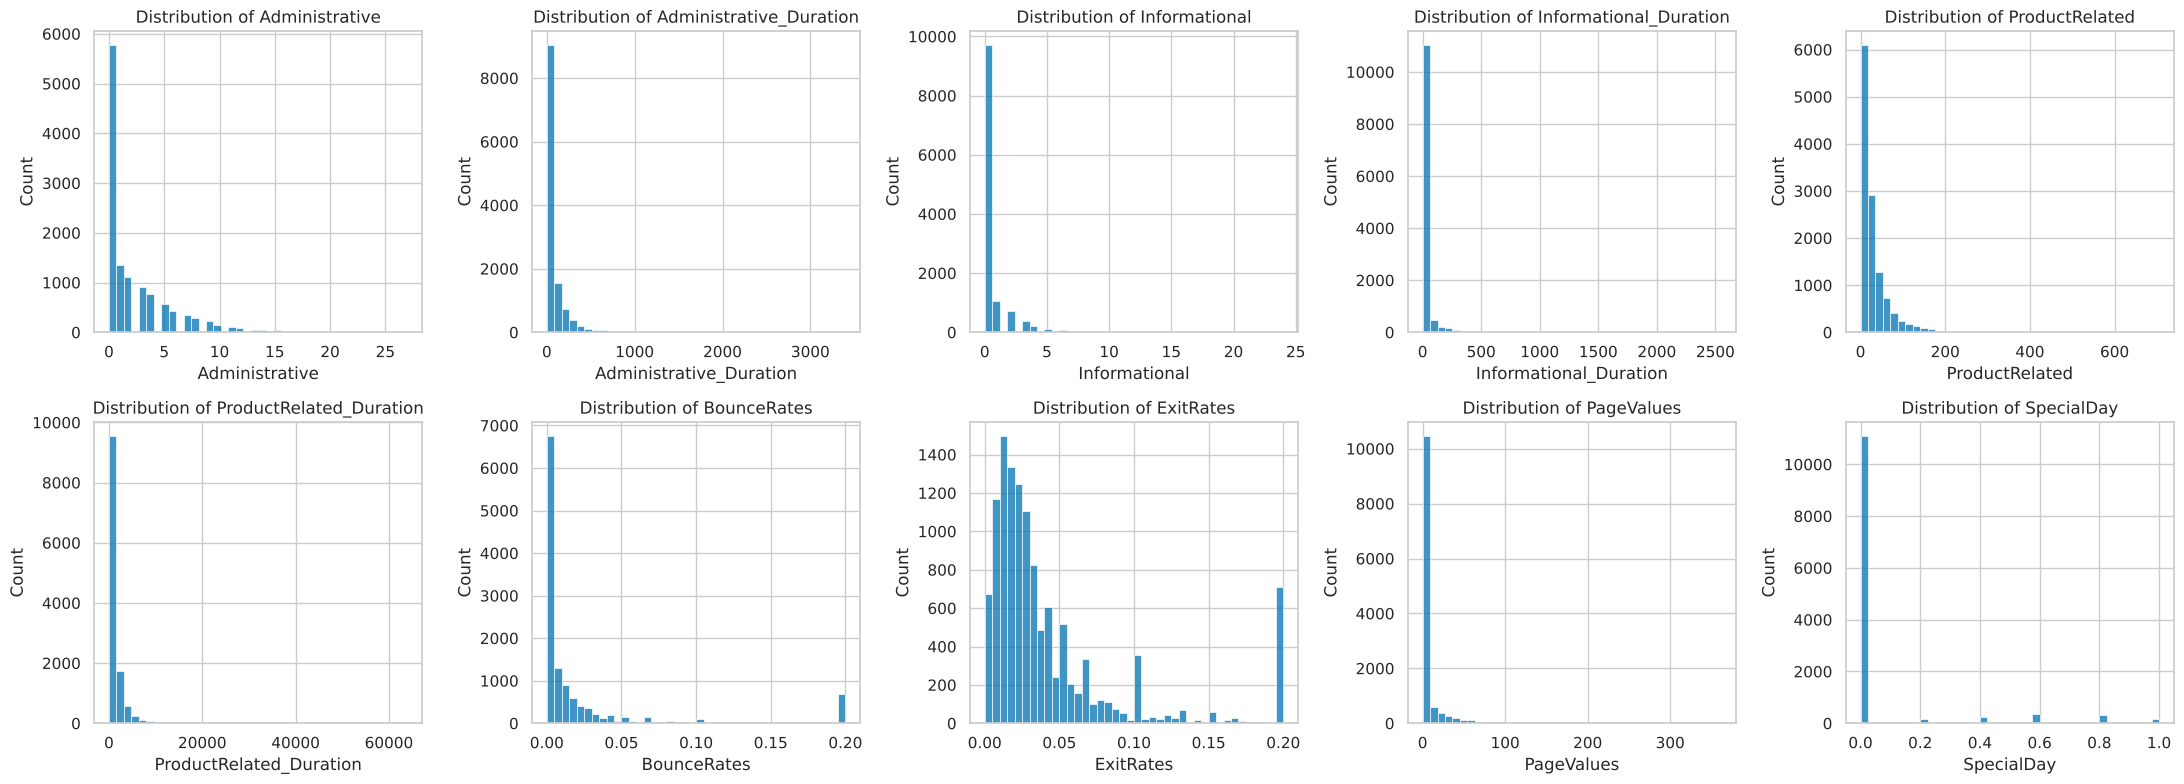

In [5]:
BEHAVIOUR_COLS = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
                  'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.ravel(), BEHAVIOUR_COLS):
    sns.histplot(df[col], bins=40, ax=ax, color='#0072B2')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col); ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig('clu_feature_distributions.png', bbox_inches='tight')
plt.show()

**Insight:** Every behavioural feature is extremely **right-skewed and zero-inflated**: 47% of sessions never visit an
administrative page, 79% never visit an informational page, and 78% have `PageValues = 0` (they never reach a page that leads to a
transaction). A few sessions view 700+ product pages or stay over 17 hours. Fed raw into a distance-based algorithm, these tails would
dominate every distance calculation — the extreme sessions would become their own clusters.

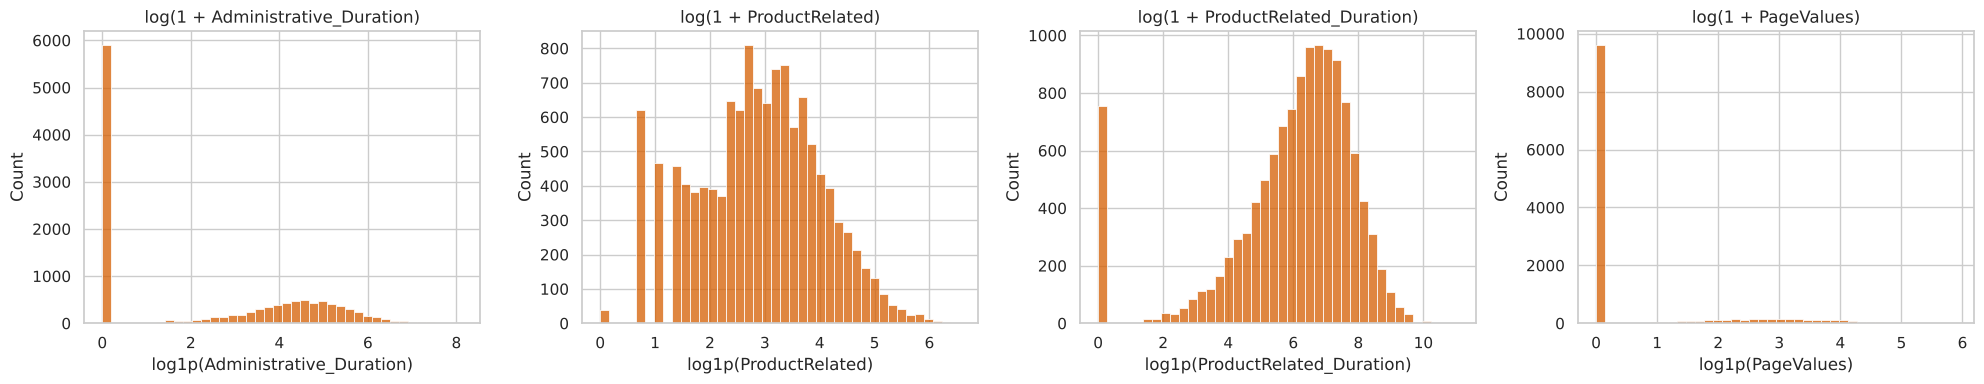

In [6]:
LOG_VIEW = ['Administrative_Duration', 'ProductRelated', 'ProductRelated_Duration', 'PageValues']
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, LOG_VIEW):
    sns.histplot(np.log1p(df[col]), bins=40, ax=ax, color='#D55E00')
    ax.set_title(f'log(1 + {col})')
    ax.set_xlabel(f'log1p({col})'); ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig('clu_log_distributions.png', bbox_inches='tight')
plt.show()

**Insight:** `log1p` turns the long tails into compact, roughly bell-shaped distributions (e.g. `ProductRelated` and
its duration now peak around 20 pages / ~15 minutes) while keeping zero at zero. The spike at 0 for `PageValues` remains — that split
between sessions that reach a valuable page and those that never do is a real behavioural difference, and exactly the kind of structure
clustering should pick up. This motivates the `log1p → StandardScaler` preprocessing in B3.

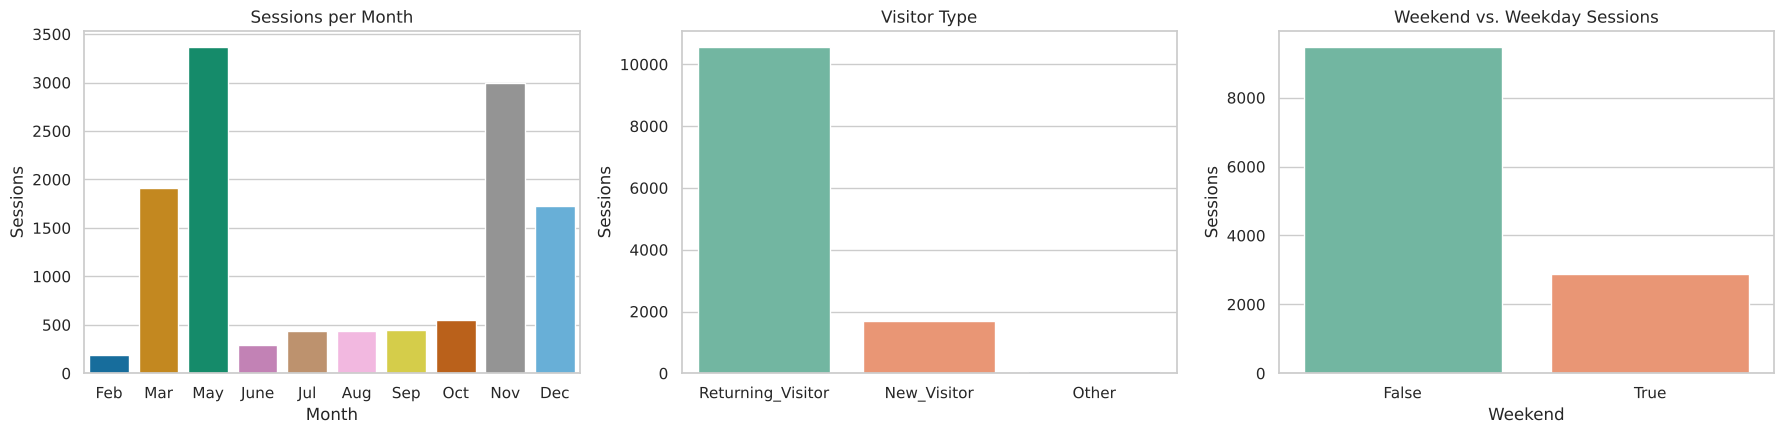

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sns.countplot(data=df, x='Month', order=month_order, hue='Month', palette='colorblind', legend=False, ax=axes[0])
axes[0].set_title('Sessions per Month'); axes[0].set_xlabel('Month'); axes[0].set_ylabel('Sessions')
sns.countplot(data=df, x='VisitorType', hue='VisitorType', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Visitor Type'); axes[1].set_xlabel(''); axes[1].set_ylabel('Sessions')
sns.countplot(data=df, x='Weekend', hue='Weekend', palette='Set2', legend=False, ax=axes[2])
axes[2].set_title('Weekend vs. Weekday Sessions'); axes[2].set_xlabel('Weekend'); axes[2].set_ylabel('Sessions')
plt.tight_layout()
plt.savefig('clu_categorical_distributions.png', bbox_inches='tight')
plt.show()

**Insight:** Traffic is very seasonal — May (3,364) and November (2,998) dominate, there is no data at all for January
and April, and February is tiny. 85.6% of sessions are **returning** visitors and only 23.3% happen at weekends. These context variables
are not clustered on, but they are used in Section G to describe who ends up in each segment.

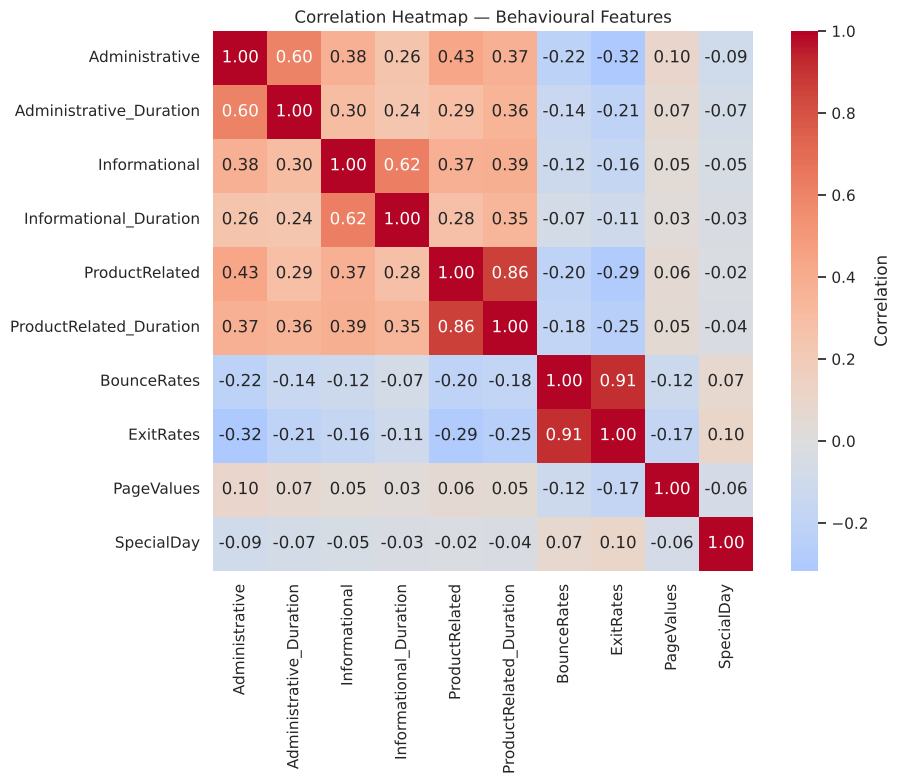

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[BEHAVIOUR_COLS].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True,
            cbar_kws={'label': 'Correlation'})
plt.title('Correlation Heatmap — Behavioural Features')
plt.tight_layout()
plt.savefig('clu_correlation_heatmap.png', bbox_inches='tight')
plt.show()

**Insight:** Two strongly redundant pairs stand out: `BounceRates`–`ExitRates` (**0.91**) and `ProductRelated`–
`ProductRelated_Duration` (**0.86**); each page-count is also moderately correlated with its own duration (0.60–0.62). `PageValues` is
almost uncorrelated with everything else (|r| ≤ 0.17), so it carries unique information. This redundancy is why Section B2 condenses the
six count/duration columns into volume (`total_pages`), depth (`avg_time_per_page`) and focus (`product_share`) instead of clustering on
all of them.

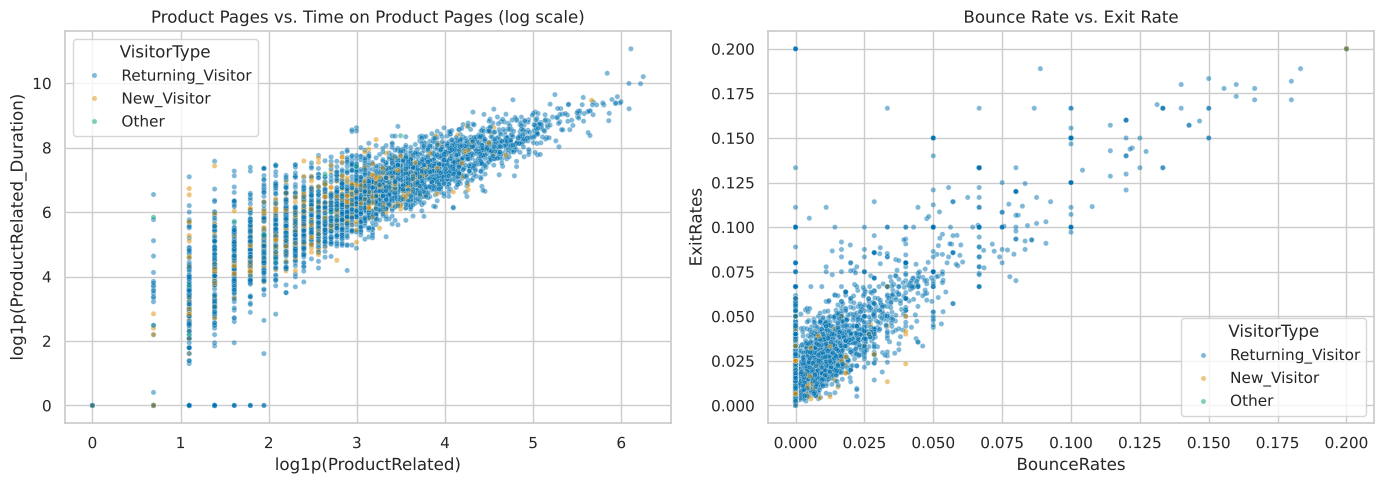

In [9]:
sample = df.sample(4000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=sample, x=np.log1p(sample['ProductRelated']), y=np.log1p(sample['ProductRelated_Duration']),
                hue='VisitorType', palette='colorblind', alpha=0.5, s=14, ax=axes[0])
axes[0].set_title('Product Pages vs. Time on Product Pages (log scale)')
axes[0].set_xlabel('log1p(ProductRelated)'); axes[0].set_ylabel('log1p(ProductRelated_Duration)')

sns.scatterplot(data=sample, x='BounceRates', y='ExitRates', hue='VisitorType', palette='colorblind', alpha=0.5, s=14, ax=axes[1])
axes[1].set_title('Bounce Rate vs. Exit Rate')
axes[1].set_xlabel('BounceRates'); axes[1].set_ylabel('ExitRates')
plt.tight_layout()
plt.savefig('clu_scatter_pairs.png', bbox_inches='tight')
plt.show()

**Insight:** On a log scale, product pages and product time rise together almost linearly — visit *volume* is one
dominant direction of variation. The bounce/exit plot shows a dense cloud of engaged sessions near (0, 0.02) and a separate pile-up at
exactly (0.2, 0.2) — the maximum — which are one-page sessions that left immediately (700 sessions have `BounceRates = 0.2`). That
separate group is a natural cluster the algorithms should find. New and returning visitors overlap heavily, so visitor type alone does
not explain behaviour.

## Section B — Data Cleaning & Feature Engineering

### B1. Data Cleaning

In [10]:
dupes = df[df.duplicated(keep=False)]
print(f"{df.duplicated().sum()} duplicate rows ({len(dupes)} rows involved). What do they look like?\n")
print(dupes[['Administrative', 'Informational', 'ProductRelated', 'ProductRelated_Duration',
             'BounceRates', 'ExitRates', 'PageValues']].describe().loc[['mean', 'min', 'max']].round(3))

125 duplicate rows (201 rows involved). What do they look like?

      Administrative  Informational  ProductRelated  ProductRelated_Duration  \
mean             0.0            0.0            1.06                      0.0   
min              0.0            0.0            1.00                      0.0   
max              0.0            0.0            2.00                      0.0   

      BounceRates  ExitRates  PageValues  
mean          0.2        0.2         0.0  
min           0.2        0.2         0.0  
max           0.2        0.2         0.0  


**Strategy — duplicates are kept:** all 201 rows involved are the *same kind* of session: 1–2 product pages, zero
duration, bounce and exit rate 0.2, no page value — instant one-page exits. Because this dataset has **no session/user ID** and every
row is documented as a different user, identical rows are expected for such minimal sessions (there are only so many ways to view one
page for zero seconds). Dropping them would under-count the very "bouncer" behaviour we want to segment, so they are retained.

In [11]:
# Outlier check via the IQR rule (report only) on the behavioural features
for col in BEHAVIOUR_COLS:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:25s}: {n_out:5d} IQR outliers ({n_out / len(df):.1%})")

Administrative           :   404 IQR outliers (3.3%)
Administrative_Duration  :  1172 IQR outliers (9.5%)
Informational            :  2631 IQR outliers (21.3%)
Informational_Duration   :  2405 IQR outliers (19.5%)
ProductRelated           :   987 IQR outliers (8.0%)
ProductRelated_Duration  :   961 IQR outliers (7.8%)
BounceRates              :  1551 IQR outliers (12.6%)
ExitRates                :  1099 IQR outliers (8.9%)
PageValues               :  2730 IQR outliers (22.1%)
SpecialDay               :  1251 IQR outliers (10.1%)


**Strategy — outliers are transformed, not removed:** the IQR rule flags 3–22% of rows per feature, which simply
reflects zero-inflated, long-tailed distributions (for `PageValues`, *every* non-zero value is "outside" an IQR of 0). These are real
power users, not data errors — deleting a fifth of the data would remove the most commercially interesting sessions. Instead, `log1p`
compresses the tails so they still inform the clusters without dominating them, and all features are standardised.

### B2. Feature Engineering

In [12]:
def add_session_features(frame):
    """Session-level behaviour features. Also used verbatim by the web app (app/utils.py) for new sessions."""
    out = frame.copy()
    out['total_pages'] = out['Administrative'] + out['Informational'] + out['ProductRelated']
    out['total_duration'] = out['Administrative_Duration'] + out['Informational_Duration'] + out['ProductRelated_Duration']
    has_pages = out['total_pages'] > 0
    # Average seconds per page: depth of attention, independent of how many pages were viewed.
    out['avg_time_per_page'] = np.where(has_pages, out['total_duration'] / out['total_pages'].where(has_pages, 1), 0.0)
    # Share of the visit spent on product pages: 'shopping' vs 'account/info' intent.
    out['product_share'] = np.where(has_pages, out['ProductRelated'] / out['total_pages'].where(has_pages, 1), 0.0)
    return out

df_feat = add_session_features(df)
df_feat[['total_pages', 'total_duration', 'avg_time_per_page', 'product_share']].describe().round(2)

,total_pages,total_duration,avg_time_per_page,product_share
count,12330.00,12330.00,12330.00,12330.00
mean,34.55,1310.04,37.79,0.91
std,46.51,2037.80,43.42,0.14
min,0.00,0.00,0.00,0.00
25%,8.00,222.00,18.23,0.86
50%,20.00,680.00,29.69,0.96
75%,42.00,1626.91,45.42,1.00
max,746.00,69921.65,1411.00,1.00


**Justification — why these features, and why only six of them go into the clustering:**
- The six raw page-count / duration columns are strongly inter-correlated (heatmap above: e.g. `ProductRelated` vs its duration ≈ 0.86).
  K-Means uses Euclidean distance, so feeding all of them in would let one underlying idea — *"how big was the visit"* — be counted
  five or six times and swamp everything else.
- They are therefore summarised into **`total_pages`** (visit *volume*) and **`avg_time_per_page`** (visit *depth*: skimming vs reading),
  plus **`product_share`** (what the visit was *about*: shopping vs account/information pages).
- **`BounceRates`, `ExitRates`** capture disengagement and **`PageValues`** captures how close the visitor got to a transaction page.

| Clustering feature | Behaviour it measures | Transform |
|---|---|---|
| `total_pages` | visit volume | log1p → standardise |
| `avg_time_per_page` | attention depth | log1p → standardise |
| `PageValues` | closeness to checkout | log1p → standardise |
| `BounceRates` | single-page exits | standardise |
| `ExitRates` | exit tendency | standardise |
| `product_share` | shopping vs. info intent | standardise |

`SpecialDay`, `Month`, `VisitorType`, `Weekend` and the technical IDs (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) are
*context*, not behaviour — they are kept aside and used in Section G to describe the segments.

### B3. Transformation & Scaling

In [13]:
LOG_COLS = ['total_pages', 'avg_time_per_page', 'PageValues']        # heavy right tails -> log1p first
RATE_COLS = ['BounceRates', 'ExitRates', 'product_share']             # already bounded in [0, 1] / [0, 0.2]
CLUSTER_FEATURES = LOG_COLS + RATE_COLS

# Fresh, independent preprocessor per use (same factory pattern as the regression/classification notebooks).
def make_preprocessor():
    return ColumnTransformer([
        ('log', Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                          ('scale', StandardScaler())]), LOG_COLS),
        ('rate', StandardScaler(), RATE_COLS)
    ])

preprocessor = make_preprocessor()
X = preprocessor.fit_transform(df_feat[CLUSTER_FEATURES])
print("Clustering matrix:", X.shape)
pd.DataFrame(X, columns=CLUSTER_FEATURES).describe().loc[['mean', 'std', 'min', 'max']].round(2)

Clustering matrix: (12330, 6)


,total_pages,avg_time_per_page,PageValues,BounceRates,ExitRates,product_share
mean,0.00,-0.00,-0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.68,-3.12,-0.49,-0.46,-0.89,-6.38
max,3.25,3.81,4.16,3.67,3.23,0.67


**Why scaling is mandatory here, and why there is no train/test split:** both algorithms are distance-based, so without
standardisation `total_pages` (up to ~750) would completely dominate `BounceRates` (≤ 0.2). `log1p` first pulls in the long right tails
so that a handful of 700-page sessions don't become their own clusters. Clustering has **no target to leak**, so there is no
train/test split: the preprocessor and the models are fitted on all 12,330 sessions, which is the standard unsupervised setting.
The `Revenue` label is not part of `X` at any point.

## Section C — Algorithm 1: K-Means Clustering

### C1. Choosing *k*: Elbow curve + Silhouette

In [14]:
from sklearn.cluster import KMeans

k_range = range(2, 11)
elbow = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    elbow.append({'k': k, 'Inertia': km.inertia_,
                  'Silhouette': silhouette_score(X, km.labels_),
                  'Davies-Bouldin': davies_bouldin_score(X, km.labels_),
                  'Calinski-Harabasz': calinski_harabasz_score(X, km.labels_),
                  'Smallest cluster %': np.bincount(km.labels_).min() / len(X) * 100})
elbow_df = pd.DataFrame(elbow).set_index('k')
elbow_df.style.format({'Inertia': '{:,.0f}', 'Silhouette': '{:.4f}', 'Davies-Bouldin': '{:.4f}',
                       'Calinski-Harabasz': '{:,.0f}', 'Smallest cluster %': '{:.1f}'})

,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster %
k,,,,,
2,"44,384",0.6142,0.5110,"8,220",7.3
3,"32,440",0.3765,0.9095,"7,892",7.1
4,"25,276",0.3903,0.9052,"7,917",7.0
5,"19,892",0.3449,0.9581,"8,378",6.5
6,"17,779",0.3139,1.0222,"7,792",5.9
7,"16,184",0.3130,1.0197,"7,334",4.7
8,"15,008",0.3015,1.0665,"6,917",3.9
9,"13,910",0.2899,1.1432,"6,651",4.3
10,"12,933",0.2705,1.1469,"6,461",3.8


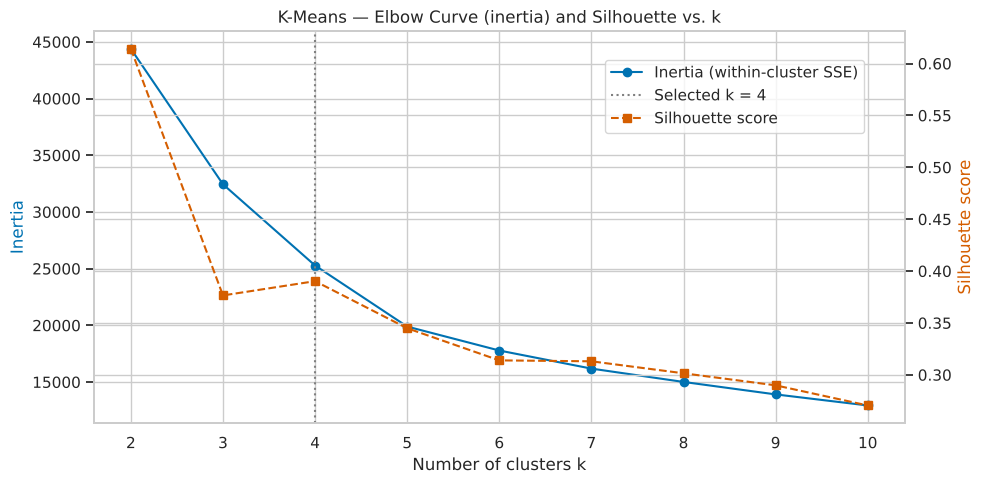

In [15]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(elbow_df.index, elbow_df['Inertia'], 'o-', color='#0072B2', label='Inertia (within-cluster SSE)')
ax1.set_xlabel('Number of clusters k'); ax1.set_ylabel('Inertia', color='#0072B2')
ax2 = ax1.twinx()
ax2.plot(elbow_df.index, elbow_df['Silhouette'], 's--', color='#D55E00', label='Silhouette score')
ax2.set_ylabel('Silhouette score', color='#D55E00')
ax1.axvline(4, color='grey', linestyle=':', label='Selected k = 4')
fig.legend(loc='upper right', bbox_to_anchor=(0.88, 0.88))
plt.title('K-Means — Elbow Curve (inertia) and Silhouette vs. k')
plt.tight_layout()
plt.savefig('clu_kmeans_elbow.png', bbox_inches='tight')
plt.show()

**Choosing k = 4:** inertia falls steeply at first (−11.9k from k = 2→3, −7.2k for 3→4, −5.4k for 4→5) and then
flattens (only −2.1k for 5→6 and less after), so the elbow sits at **k = 4–5**. The Silhouette score is highest at k = 2 (0.614) — but that solution
just splits off the ~7% one-page bouncers from everyone else, which is obvious and not actionable. Among k ≥ 3, **k = 4 has both the best
Silhouette (0.390) and the lowest Davies-Bouldin index (0.905)**, and it sits at the elbow — three independent signals agree, so k = 4
is used for both algorithms.

### C2. Final K-Means model

In [16]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE)
km_labels = kmeans.fit_predict(X)

clu_results = []

def evaluate(name, labels, extra=None):
    row = {'Algorithm': name,
           'Silhouette ↑': silhouette_score(X, labels),
           'Davies-Bouldin ↓': davies_bouldin_score(X, labels),
           'Calinski-Harabasz ↑': calinski_harabasz_score(X, labels),
           'Cluster sizes': sorted(np.bincount(labels).tolist(), reverse=True)}
    row.update(extra or {})
    clu_results.append(row)
    return row

r = evaluate('K-Means (k=4)', km_labels)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})
print("\nCluster sizes:", dict(zip(*np.unique(km_labels, return_counts=True))))

{'Algorithm': 'K-Means (k=4)', 'Silhouette ↑': 0.3903, 'Davies-Bouldin ↓': 0.9052, 'Calinski-Harabasz ↑': 7917.0998, 'Cluster sizes': [7461, 2537, 1469, 863]}

Cluster sizes: {np.int32(0): np.int64(7461), np.int32(1): np.int64(863), np.int32(2): np.int64(2537), np.int32(3): np.int64(1469)}


## Section D — Algorithm 2: Agglomerative Hierarchical Clustering

### D1. Dendrogram (Ward linkage)
`scipy.cluster.hierarchy.linkage` builds the full merge tree for all 12,330 sessions; the dendrogram is truncated to the last 30
merges so it stays readable. The red line marks the height at which the tree is cut into 4 clusters.

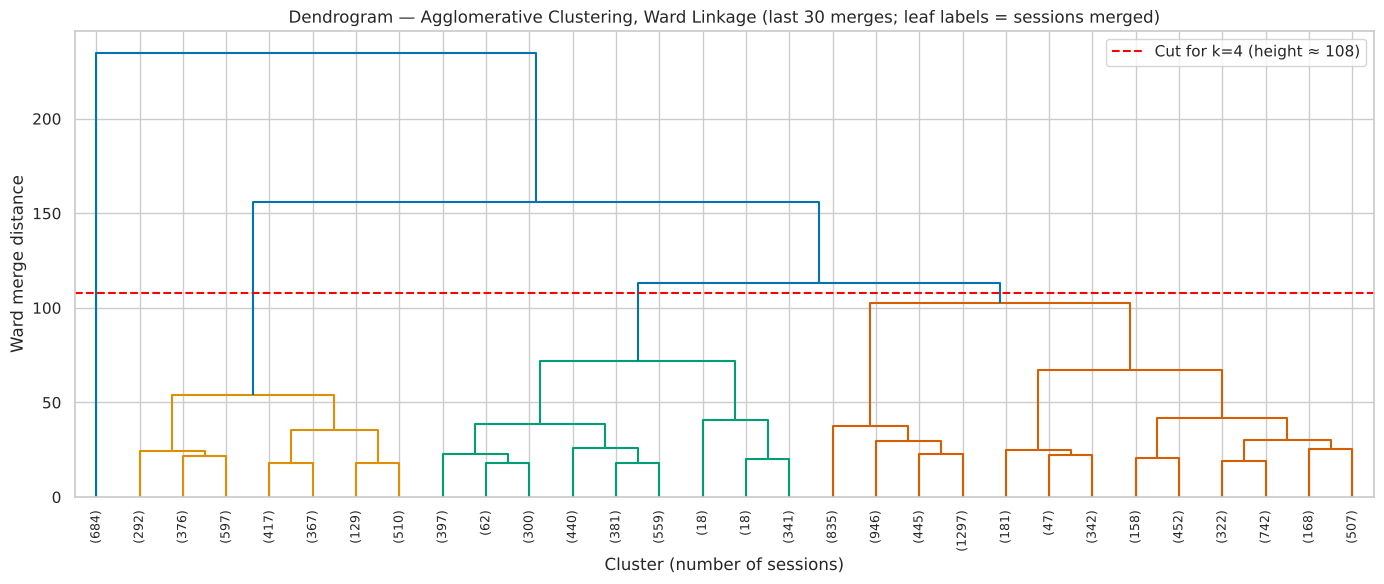

Heights of the last 8 merges (largest first): [234.7 155.9 113.2 102.4  71.9  67.4  53.7  41.7]


In [17]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z_ward = linkage(X, method='ward')
cut_height = (Z_ward[-K, 2] + Z_ward[-K + 1, 2]) / 2      # midway between the merges that go from 4 -> 3 clusters

plt.figure(figsize=(14, 6))
dendrogram(Z_ward, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=9,
           color_threshold=cut_height)
plt.axhline(cut_height, color='red', linestyle='--', label=f'Cut for k={K} (height ≈ {cut_height:.0f})')
plt.title('Dendrogram — Agglomerative Clustering, Ward Linkage (last 30 merges; leaf labels = sessions merged)')
plt.xlabel('Cluster (number of sessions)'); plt.ylabel('Ward merge distance')
plt.legend()
plt.tight_layout()
plt.savefig('clu_dendrogram_ward.png', bbox_inches='tight')
plt.show()

last_merges = Z_ward[-8:, 2][::-1]
print("Heights of the last 8 merges (largest first):", np.round(last_merges, 1))

**Insight:** The tree has one very tall final merge (height ≈ 235): the 684-session branch on the far left (the
bouncers) is the last thing to join everything else — the same "most separated group" that K-Means found. The last merge heights are 235, 156, 113, 102, 72, 67…: the
top three merges join very different groups, and cutting just below them at ≈ 108 (the red line) gives **4 branches** — the bouncers,
the high-intent shoppers (orange), the account/info seekers (green) and the large browser group (red), consistent with k = 4 from
the elbow curve. (Cutting at ≈ 130 would give 3 clusters; below ≈ 70 the merges become small and similar, i.e. no natural structure.) (The 684-session bouncer branch is a single leaf above the cut, so it is drawn in the
default blue rather than its own colour.)

### D2. Comparing linkage strategies
The four linkage rules differ in how they define the distance between two clusters: **ward** merges the pair that least increases
within-cluster variance (same objective as K-Means); **complete** uses the *farthest* pair of points; **average** the mean pairwise
distance; **single** the *closest* pair of points.

In [18]:
from sklearn.cluster import AgglomerativeClustering

linkage_rows = []
agg_labels = {}
for link in ['ward', 'complete', 'average', 'single']:
    labels = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(X)
    agg_labels[link] = labels
    sizes = np.bincount(labels)
    linkage_rows.append({'Linkage': link,
                         'Silhouette ↑': silhouette_score(X, labels),
                         'Davies-Bouldin ↓': davies_bouldin_score(X, labels),
                         'Calinski-Harabasz ↑': calinski_harabasz_score(X, labels),
                         'Largest cluster %': sizes.max() / len(X) * 100,
                         'Smallest cluster size': sizes.min(),
                         'Cluster sizes': sorted(sizes.tolist(), reverse=True)})
linkage_df = pd.DataFrame(linkage_rows).set_index('Linkage')
linkage_df.style.format({'Silhouette ↑': '{:.4f}', 'Davies-Bouldin ↓': '{:.4f}', 'Calinski-Harabasz ↑': '{:,.0f}',
                         'Largest cluster %': '{:.1f}'})

,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,Largest cluster %,Smallest cluster size,Cluster sizes
Linkage,,,,,,
ward,0.3127,1.0749,"6,788",52.2,684,"[6442, 2688, 2516, 684]"
complete,0.3771,0.7584,"3,636",84.5,19,"[10413, 1161, 737, 19]"
average,0.4328,0.5846,"3,590",90.6,19,"[11176, 684, 451, 19]"
single,0.4624,0.3358,86,99.8,1,"[12310, 18, 1, 1]"


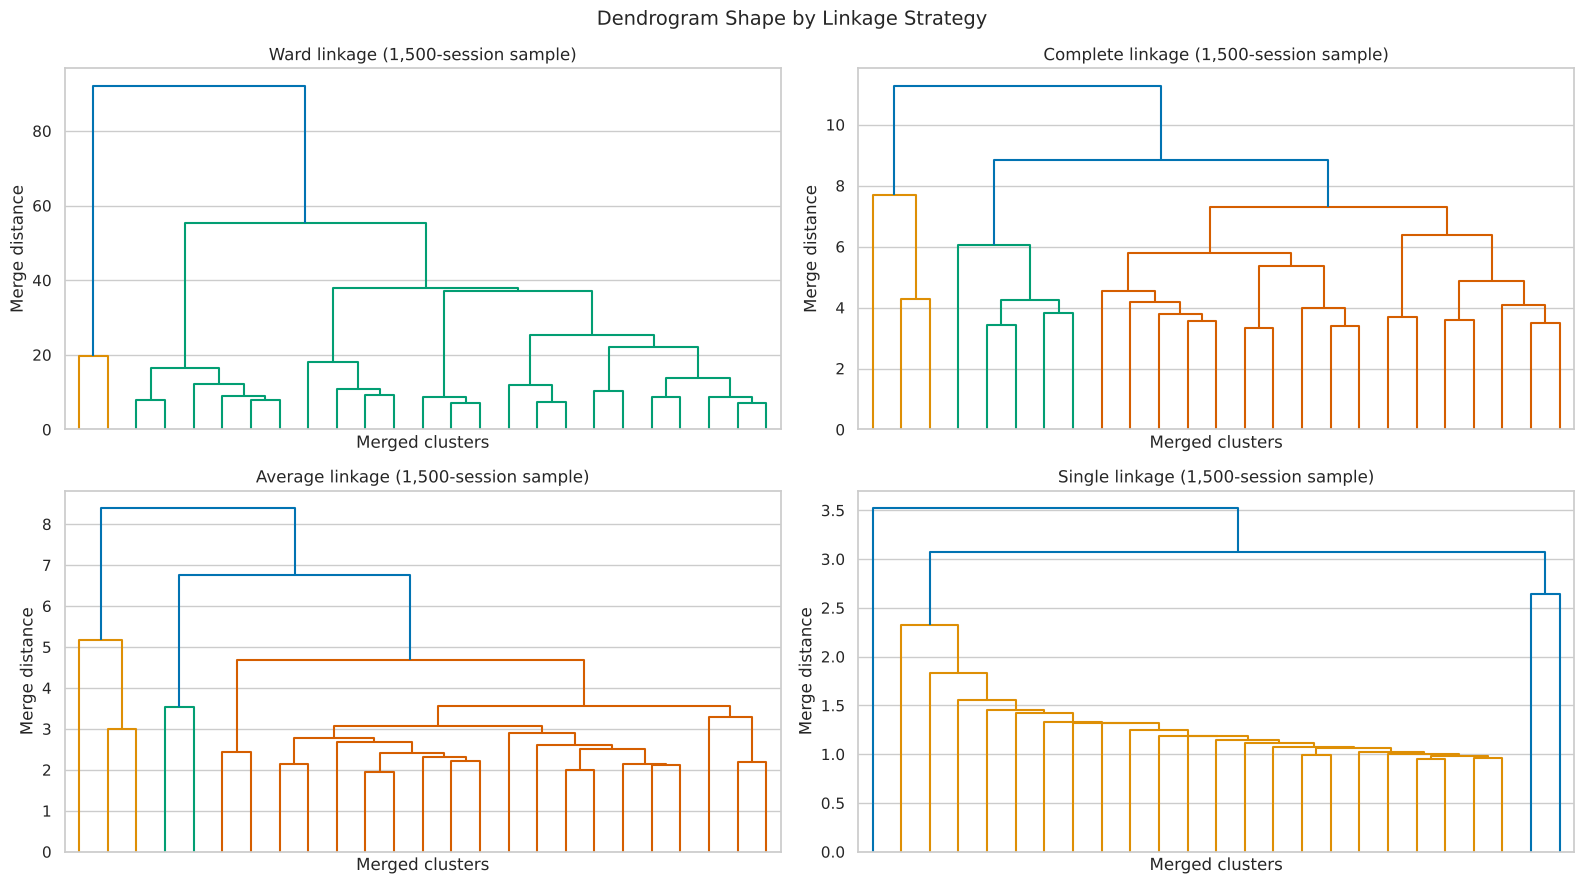

In [19]:
# Visual comparison of the four linkage trees on a random 1,500-session sample (full-data trees are unreadable for single/average)
sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X), 1500, replace=False)
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, link in zip(axes.ravel(), ['ward', 'complete', 'average', 'single']):
    dendrogram(linkage(X[sample_idx], method=link), truncate_mode='lastp', p=25, no_labels=True, ax=ax)
    ax.set_title(f'{link.capitalize()} linkage (1,500-session sample)')
    ax.set_ylabel('Merge distance'); ax.set_xlabel('Merged clusters')
plt.suptitle('Dendrogram Shape by Linkage Strategy', fontsize=14)
plt.tight_layout()
plt.savefig('clu_dendrogram_linkages.png', bbox_inches='tight')
plt.show()

**Insight — why single linkage "wins" the metrics but is useless:** single linkage scores the best Silhouette
(0.462) and Davies-Bouldin (0.336), yet its clusters are **12,310 / 18 / 1 / 1** — one giant blob and three outliers. Merging by the
*closest pair of points* causes "chaining": dense regions get joined through thin bridges of points, so only isolated outliers stay
separate. Average (90.6% in one cluster) and complete (84.5%) linkage suffer the same problem to a lesser degree. Their tree shapes above
show it too — long thin "staircases" instead of balanced branches. **Ward** is the only linkage that produces a balanced, usable
segmentation (6,442 / 2,688 / 2,516 / 684) because, like K-Means, it minimises within-cluster variance. Lesson: internal metrics must be
read **alongside cluster sizes**, never on their own.

In [20]:
# Selection rule: a usable segmentation must not be degenerate -> every cluster >= 2% of sessions and none > 85%.
# Among the linkages that pass, pick the highest Silhouette.
usable = linkage_df[(linkage_df['Smallest cluster size'] >= 0.02 * len(X)) & (linkage_df['Largest cluster %'] <= 85)]
print("Linkages passing the non-degeneracy rule:", usable.index.tolist())
BEST_LINKAGE = usable['Silhouette ↑'].idxmax()
print("Selected linkage:", BEST_LINKAGE)

agg_final = agg_labels[BEST_LINKAGE]
for link in ['ward', 'complete', 'average', 'single']:
    evaluate(f'Agglomerative ({link}, k=4)', agg_labels[link])

Linkages passing the non-degeneracy rule: ['ward']
Selected linkage: ward


## Section E — Evaluation: All Algorithms, All Three Metrics

In [21]:
clu_results_df = pd.DataFrame(clu_results)
clu_results_df['Degenerate?'] = clu_results_df['Cluster sizes'].apply(lambda s: 'yes' if min(s) < 0.02 * len(X) else 'no')
clu_results_df.index = range(1, len(clu_results_df) + 1)
(clu_results_df.style
    .format({'Silhouette ↑': '{:.4f}', 'Davies-Bouldin ↓': '{:.4f}', 'Calinski-Harabasz ↑': '{:,.0f}'})
    .apply(lambda col: ['background-color: #fde0dd' if v == 'yes' else '' for v in col], subset=['Degenerate?']))

,Algorithm,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,Cluster sizes,Degenerate?
1,K-Means (k=4),0.3903,0.9052,"7,917","[7461, 2537, 1469, 863]",no
2,"Agglomerative (ward, k=4)",0.3127,1.0749,"6,788","[6442, 2688, 2516, 684]",no
3,"Agglomerative (complete, k=4)",0.3771,0.7584,"3,636","[10413, 1161, 737, 19]",yes
4,"Agglomerative (average, k=4)",0.4328,0.5846,"3,590","[11176, 684, 451, 19]",yes
5,"Agglomerative (single, k=4)",0.4624,0.3358,86,"[12310, 18, 1, 1]",yes


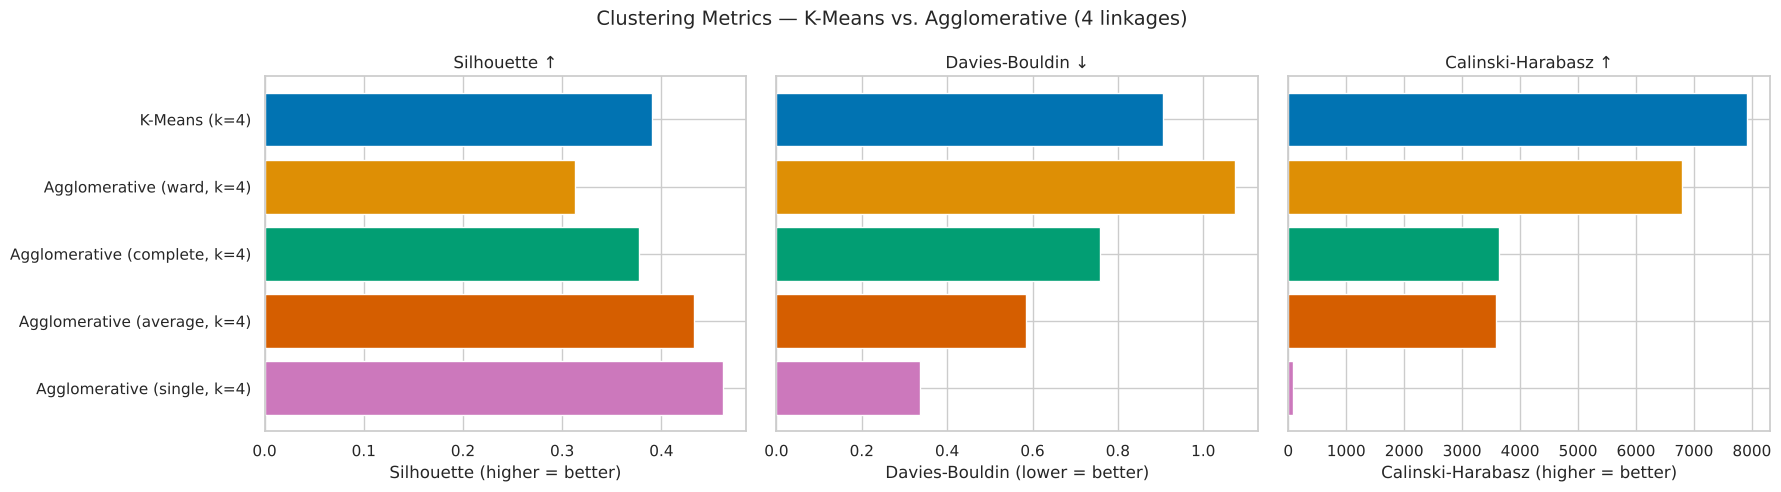

In [22]:
metric_plot = clu_results_df.set_index('Algorithm')[['Silhouette ↑', 'Davies-Bouldin ↓', 'Calinski-Harabasz ↑']]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
palette = sns.color_palette('colorblind', len(metric_plot))
for ax, col in zip(axes, metric_plot.columns):
    ax.barh(metric_plot.index, metric_plot[col], color=palette)
    ax.set_title(col); ax.set_xlabel(col.replace(' ↑', ' (higher = better)').replace(' ↓', ' (lower = better)'))
    ax.invert_yaxis()
axes[1].set_yticklabels([]); axes[2].set_yticklabels([])
plt.suptitle('Clustering Metrics — K-Means vs. Agglomerative (4 linkages)', fontsize=14)
plt.tight_layout()
plt.savefig('clu_metrics_comparison.png', bbox_inches='tight')
plt.show()

**Insight:** Comparing only the non-degenerate solutions, **K-Means beats Agglomerative-Ward on all three metrics**:
Silhouette 0.390 vs 0.313 (points sit more clearly inside their own cluster), Davies-Bouldin 0.905 vs 1.075 (clusters are more compact
relative to their separation) and Calinski-Harabasz 7,917 vs 6,788 (more between-cluster vs within-cluster variance). This is expected:
K-Means directly optimises within-cluster variance, while Ward optimises it greedily and can never undo an early merge. The degenerate
linkages (red rows) only "win" Silhouette/DB because three of their clusters contain 1–19 points; Calinski-Harabasz — which rewards
large, well-separated groups — exposes them immediately (86 for single linkage vs ~7,900 for K-Means).

## Section F — Cluster Visualisation (PCA & t-SNE)

In [23]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print(f"Explained variance: PC1 = {pca.explained_variance_ratio_[0]:.1%}, PC2 = {pca.explained_variance_ratio_[1]:.1%}, "
      f"total = {pca.explained_variance_ratio_.sum():.1%}")
pd.DataFrame(pca.components_.T, index=CLUSTER_FEATURES, columns=['PC1 loading', 'PC2 loading']).round(3)

Explained variance: PC1 = 52.1%, PC2 = 16.8%, total = 68.9%


,PC1 loading,PC2 loading
total_pages,-0.415,0.267
avg_time_per_page,-0.468,-0.016
PageValues,-0.203,0.347
BounceRates,0.517,0.092
ExitRates,0.537,0.050
product_share,0.112,0.893


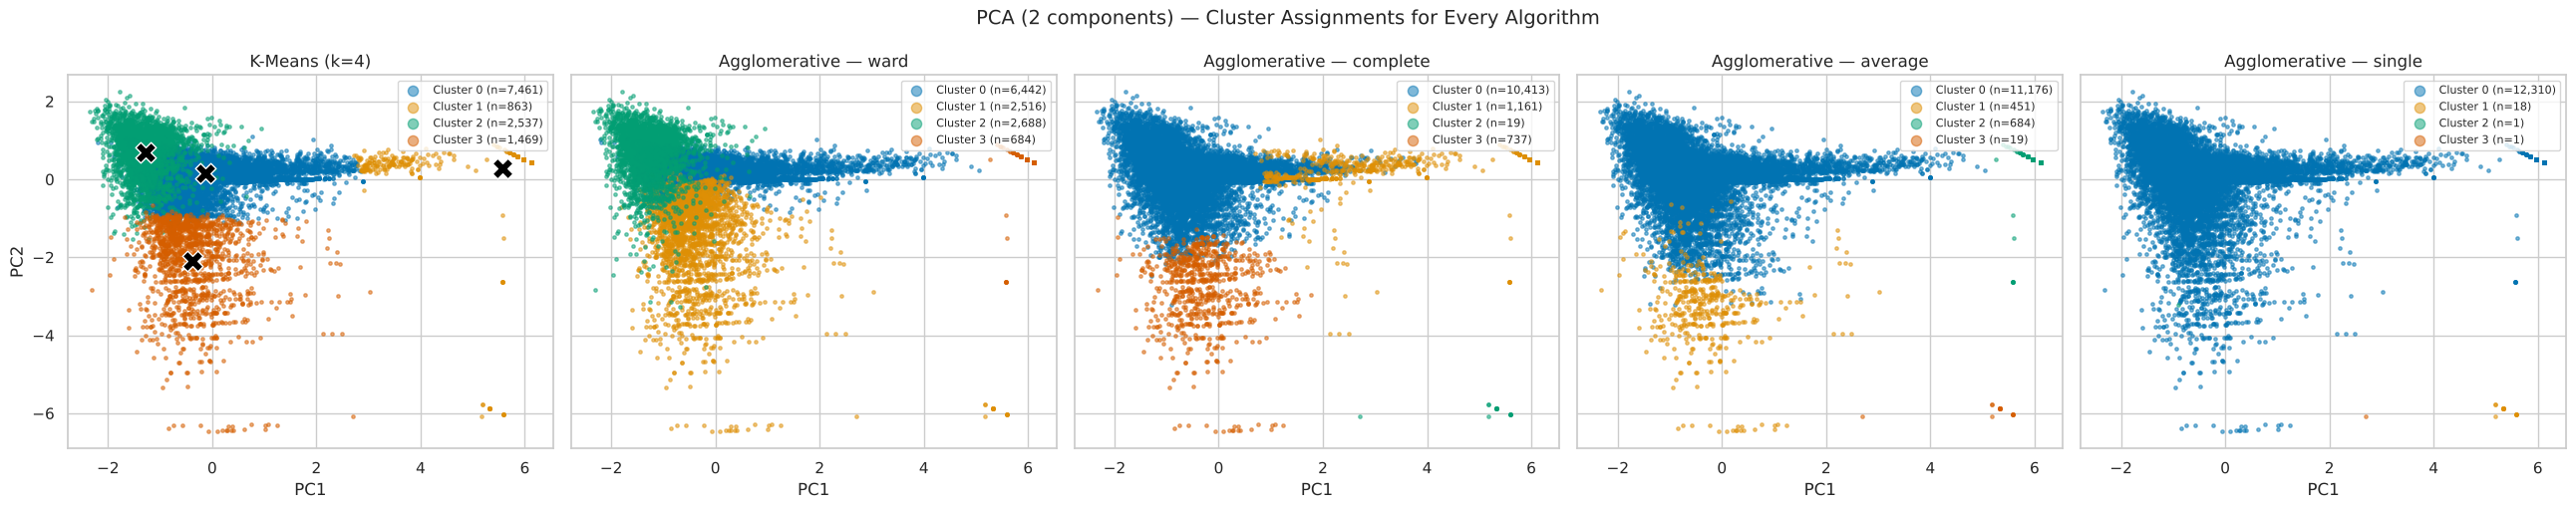

In [24]:
pca_views = [('K-Means (k=4)', km_labels)] + [(f'Agglomerative — {l}', agg_labels[l]) for l in ['ward', 'complete', 'average', 'single']]
fig, axes = plt.subplots(1, 5, figsize=(26, 5.2), sharex=True, sharey=True)
for ax, (title, labels) in zip(axes, pca_views):
    for c in np.unique(labels):
        m = labels == c
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=6, alpha=0.5, label=f'Cluster {c} (n={m.sum():,})',
                   color=sns.color_palette('colorblind')[c])
    ax.set_title(title); ax.set_xlabel('PC1')
    ax.legend(markerscale=3, fontsize=8, loc='upper right')
axes[0].set_ylabel('PC2')
# K-Means centroids projected into PCA space
cent = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(cent[:, 0], cent[:, 1], marker='X', s=220, c='black', edgecolor='white', label='Centroids')
plt.suptitle('PCA (2 components) — Cluster Assignments for Every Algorithm', fontsize=14)
plt.tight_layout()
plt.savefig('clu_pca_all.png', bbox_inches='tight')
plt.show()

**Insight:** Two principal components keep **68.9%** of the variance. PC1 (52.1%) is a *disengagement* axis — high
`BounceRates`/`ExitRates` loadings (+0.52/+0.54) against negative `total_pages`/`avg_time_per_page` loadings — so the bouncers form the
isolated group on the far right. PC2 (16.8%) is dominated by `product_share` (+0.89) and `PageValues` (+0.35): sessions focused on
account/info pages fall to the bottom, high-value shoppers rise to the top-left. K-Means and Ward recover the same four regions
(Ward simply absorbs some product browsers into its account/info cluster), whereas complete, average and single linkage collapse almost
everything into one colour.

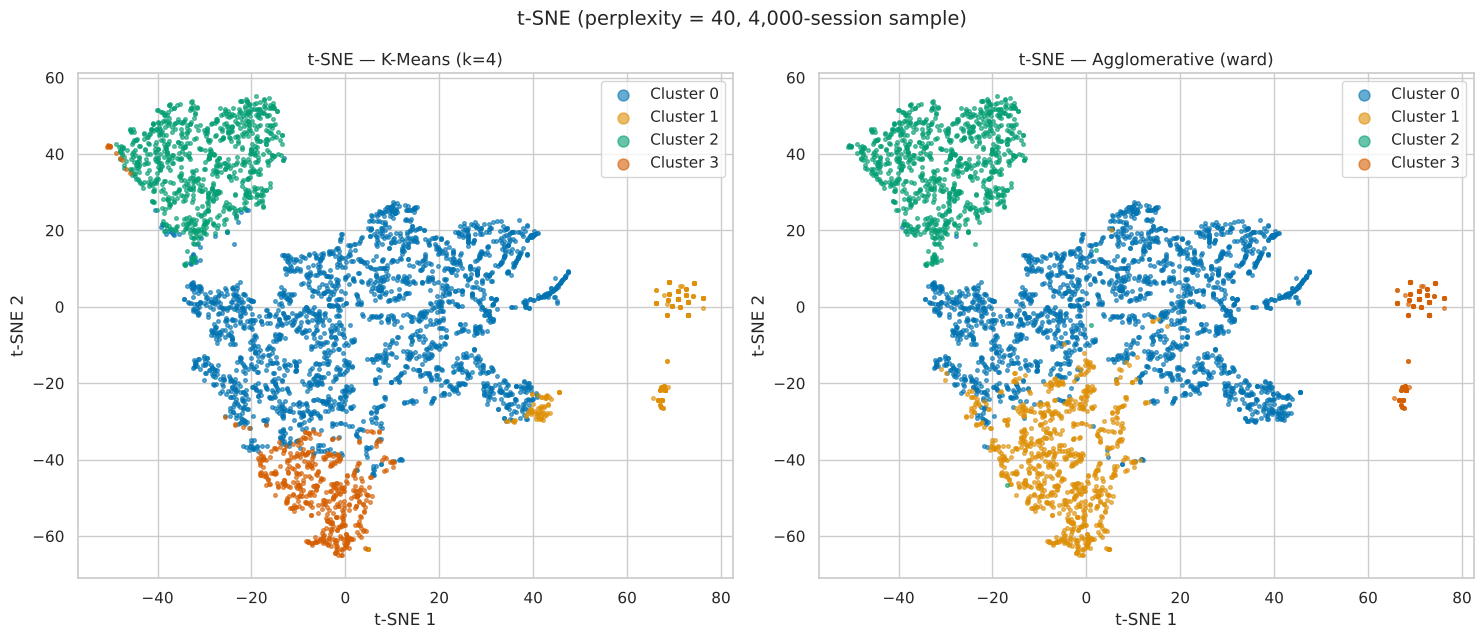

In [25]:
from sklearn.manifold import TSNE

# t-SNE is O(n log n) but still slow on 12k points with 2 CPU cores, so it is run on a 4,000-session random sample.
tsne_idx = np.random.RandomState(RANDOM_STATE).choice(len(X), 4000, replace=False)
X_tsne = TSNE(n_components=2, perplexity=40, init='pca', random_state=RANDOM_STATE).fit_transform(X[tsne_idx])

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (title, labels) in zip(axes, [('K-Means (k=4)', km_labels), (f'Agglomerative ({BEST_LINKAGE})', agg_final)]):
    lab = labels[tsne_idx]
    for c in np.unique(lab):
        m = lab == c
        ax.scatter(X_tsne[m, 0], X_tsne[m, 1], s=7, alpha=0.6, label=f'Cluster {c}', color=sns.color_palette('colorblind')[c])
    ax.set_title(f't-SNE — {title}'); ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
    ax.legend(markerscale=3)
plt.suptitle('t-SNE (perplexity = 40, 4,000-session sample)', fontsize=14)
plt.tight_layout()
plt.savefig('clu_tsne.png', bbox_inches='tight')
plt.show()

**Insight:** t-SNE, which preserves *local* neighbourhoods rather than global variance, shows the same structure even more
clearly: the high-intent shoppers form a separate island (top-left), bouncers sit far away on the right, and the account/info seekers
occupy the lower lobe of the main mass. K-Means and Ward agree almost everywhere; the only real disagreement is at the border between the
large browser group and the account/info group — consistent with their ARI of 0.71 (below).

## Section G — Interpreting the Segments & Post-hoc Validation
Clusters are only useful if they mean something. This section profiles each K-Means cluster on the original (un-scaled) features,
names it, and only **then** brings back the `Revenue` label to check whether the behavioural segments line up with real purchasing.

In [26]:
PROFILE_COLS = ['total_pages', 'total_duration', 'avg_time_per_page', 'PageValues', 'BounceRates', 'ExitRates',
                'product_share', 'Administrative', 'Informational', 'ProductRelated']
seg = df_feat.copy()
seg['cluster'] = km_labels
profile = seg.groupby('cluster')[PROFILE_COLS].mean()

# Name clusters from their profile (rule-based, so names stay correct even if cluster ids were permuted):
names = {}
c_bounce = profile['BounceRates'].idxmax();                      names[c_bounce] = 'Bouncers'
c_value = profile.drop(index=[c_bounce])['PageValues'].idxmax(); names[c_value] = 'High-Intent Shoppers'
rest = profile.drop(index=[c_bounce, c_value])
c_info = rest['product_share'].idxmin();                         names[c_info] = 'Account & Info Seekers'
c_window = rest.drop(index=[c_info]).index[0];                   names[c_window] = 'Window Shoppers'
seg['segment'] = seg['cluster'].map(names)

profile.insert(0, 'segment', profile.index.map(names))
profile.insert(1, 'sessions', seg['cluster'].value_counts().sort_index())
profile.round(3)

,segment,sessions,total_pages,total_duration,avg_time_per_page,PageValues,BounceRates,ExitRates,product_share,Administrative,Informational,ProductRelated
cluster,,,,,,,,,,,,
0,Window Shoppers,7461,33.271,1240.829,40.022,0.029,0.012,0.037,0.957,1.409,0.326,31.537
1,Bouncers,863,2.044,11.518,2.504,0.000,0.183,0.192,0.975,0.019,0.008,2.017
2,High-Intent Shoppers,2537,60.232,2366.154,42.540,28.266,0.005,0.019,0.896,4.399,1.017,54.816
3,Account & Info Seekers,1469,15.790,600.451,38.996,0.469,0.007,0.029,0.616,4.670,0.811,10.310


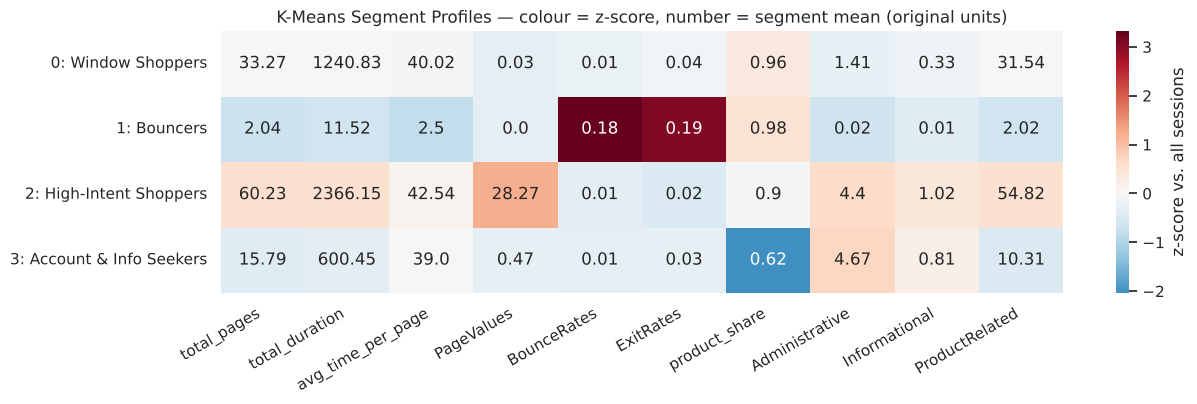

In [27]:
z = (profile[PROFILE_COLS] - seg[PROFILE_COLS].mean()) / seg[PROFILE_COLS].std()
z.index = [f'{c}: {names[c]}' for c in z.index]
plt.figure(figsize=(13, 4.2))
sns.heatmap(z, annot=profile[PROFILE_COLS].round(2).values, fmt='', cmap='RdBu_r', center=0,
            cbar_kws={'label': 'z-score vs. all sessions'})
plt.title('K-Means Segment Profiles — colour = z-score, number = segment mean (original units)')
plt.xlabel(''); plt.ylabel('')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('clu_segment_profiles.png', bbox_inches='tight')
plt.show()

**Insight — four distinct, nameable segments:**
- **High-Intent Shoppers (2,537):** the deepest visits (60 pages, ~39 min) and, crucially, an average `PageValues` of **28.3** — they
  reach the pages that lead to a purchase.
- **Window Shoppers (7,461, the majority):** long product-focused visits (33 pages, 96% product pages, ~21 min) but `PageValues` ≈ 0 —
  plenty of interest, almost never reaching checkout-adjacent pages.
- **Account & Info Seekers (1,469):** shorter visits (16 pages) with the **lowest product share (62%)** and the most administrative /
  informational pages — people managing accounts, reading policies or signing up.
- **Bouncers (863):** ~2 pages, 12 seconds, bounce and exit rates at the 0.2 maximum — they leave immediately.

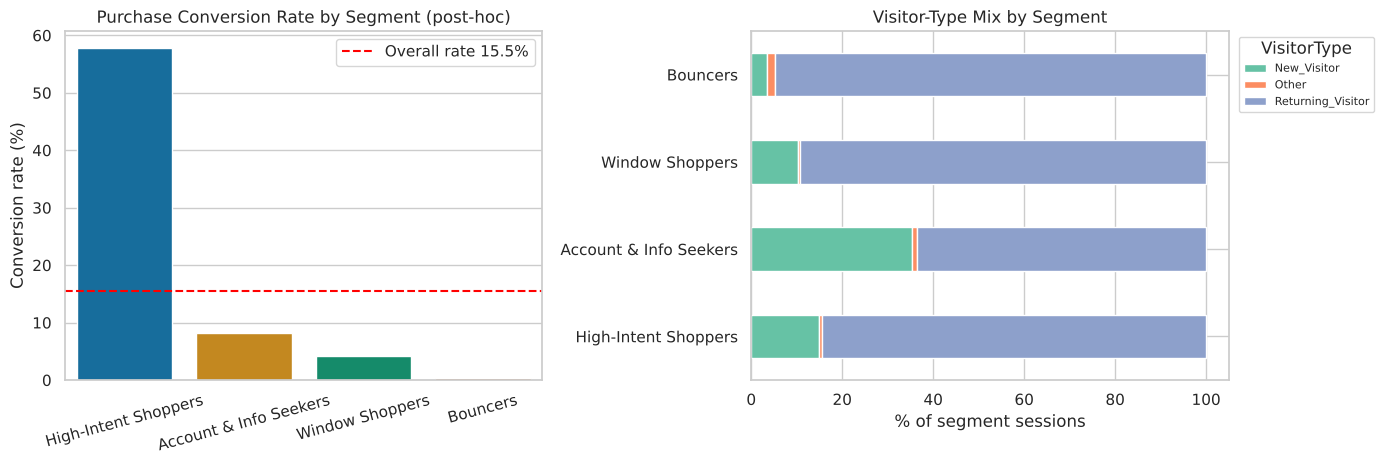

,Conversion rate,Purchases,Sessions,Share of all purchases
segment,,,,
High-Intent Shoppers,57.9%,1468,2537,76.9%
Account & Info Seekers,8.2%,120,1469,6.3%
Window Shoppers,4.2%,317,7461,16.6%
Bouncers,0.3%,3,863,0.2%


Agreement with Revenue labels — ARI: K-Means = 0.222, Agglomerative (ward) = 0.171
                              NMI: K-Means = 0.199, Agglomerative (ward) = 0.193


In [28]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# --- POST-HOC ONLY: Revenue was not used to fit anything above ---
conv = seg.groupby('segment')['Revenue'].agg(['mean', 'sum', 'count']).rename(
    columns={'mean': 'Conversion rate', 'sum': 'Purchases', 'count': 'Sessions'}).sort_values('Conversion rate', ascending=False)
conv['Share of all purchases'] = conv['Purchases'] / conv['Purchases'].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.barplot(x=conv.index, y=conv['Conversion rate'] * 100, hue=conv.index, palette='colorblind', legend=False, ax=axes[0])
axes[0].tick_params(axis='x', rotation=15)
axes[0].axhline(seg['Revenue'].mean() * 100, color='red', linestyle='--', label=f"Overall rate {seg['Revenue'].mean():.1%}")
axes[0].set_title('Purchase Conversion Rate by Segment (post-hoc)'); axes[0].set_ylabel('Conversion rate (%)'); axes[0].set_xlabel('')
axes[0].legend()
mix = pd.crosstab(seg['segment'], seg['VisitorType'], normalize='index').loc[conv.index] * 100
mix.plot(kind='barh', stacked=True, ax=axes[1], color=sns.color_palette('Set2'))
axes[1].set_title('Visitor-Type Mix by Segment'); axes[1].set_xlabel('% of segment sessions'); axes[1].set_ylabel('')
axes[1].legend(title='VisitorType', fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig('clu_segment_validation.png', bbox_inches='tight')
plt.show()

display(conv.style.format({'Conversion rate': '{:.1%}', 'Share of all purchases': '{:.1%}'}))
print(f"Agreement with Revenue labels — ARI: K-Means = {adjusted_rand_score(seg['Revenue'], km_labels):.3f}, "
      f"Agglomerative ({BEST_LINKAGE}) = {adjusted_rand_score(seg['Revenue'], agg_final):.3f}")
print(f"                              NMI: K-Means = {normalized_mutual_info_score(seg['Revenue'], km_labels):.3f}, "
      f"Agglomerative ({BEST_LINKAGE}) = {normalized_mutual_info_score(seg['Revenue'], agg_final):.3f}")

**Post-hoc validation (labels used here for the first time):** the segments separate buyers remarkably well
even though `Revenue` was never seen during fitting. **High-Intent Shoppers convert at 57.9%** — 3.7× the 15.5% site average — and,
despite being only 21% of sessions, account for **76.9% of all purchases**. Account & Info Seekers convert at 8.2%, Window Shoppers at 4.2%
and Bouncers at 0.3% (3 purchases in 863 sessions). Account & Info Seekers have by far the highest share of **new visitors (~35%)**, which
fits first-time visitors registering or reading shipping/returns information.

ARI (0.22) and NMI (0.20) against `Revenue` are modest — and that is expected, not a failure: a 4-group behavioural segmentation is not
trying to reproduce a 2-class label (Window Shoppers and Bouncers both map to "no purchase"). The conversion-rate spread is the more
meaningful validation.

In [29]:
# How similar are the two algorithms' segmentations? (contingency table, rows = K-Means segments)
agree = pd.crosstab(seg['segment'], pd.Series(agg_final, name=f'Agglomerative ({BEST_LINKAGE}) cluster'))
print(f"ARI between K-Means and Agglomerative ({BEST_LINKAGE}): {adjusted_rand_score(km_labels, agg_final):.3f}\n")
agree

ARI between K-Means and Agglomerative (ward): 0.706



Agglomerative (ward) cluster,0,1,2,3
segment,,,,
Account & Info Seekers,1,1425,43,0
Bouncers,161,18,0,684
High-Intent Shoppers,2,0,2535,0
Window Shoppers,6278,1073,110,0


**Insight:** The two algorithms agree strongly (ARI = **0.71**). High-Intent Shoppers (2,535 of 2,537) and
Account & Info Seekers (1,425 of 1,469) map almost one-to-one onto a single Ward cluster. The main differences: Ward puts 1,073 Window
Shoppers into the account/info cluster, and moves 161 near-bouncers into the big browser cluster — boundary decisions between groups that
are genuinely adjacent in feature space.

## Section H — Saving the Segmentation Model for the Web App
Agglomerative clustering has no `predict()` — it can only label the points it was built on — so the deployable model is
**K-Means**: a new session is pushed through the same `log1p → StandardScaler` preprocessor and assigned to its nearest centroid.
The fitted PCA is saved too, so the app can drop a new session onto the same 2-D map shown above.

In [30]:
import os, json, joblib

MODELS_DIR = '../models'
os.makedirs(MODELS_DIR, exist_ok=True)

segment_pipe = Pipeline([('pre', preprocessor), ('kmeans', kmeans)])   # both already fitted above
assert (segment_pipe.predict(df_feat[CLUSTER_FEATURES]) == km_labels).all()
joblib.dump({'pipeline': segment_pipe, 'pca': pca}, f'{MODELS_DIR}/shopper_segmenter.joblib', compress=3)

# PCA map sample for the app (3,000 sessions) + per-segment profile/conversion + metrics table
map_idx = np.random.RandomState(RANDOM_STATE).choice(len(X), 3000, replace=False)
pd.DataFrame({'PC1': X_pca[map_idx, 0], 'PC2': X_pca[map_idx, 1], 'cluster': km_labels[map_idx],
              'segment': seg['segment'].values[map_idx]}).to_csv(f'{MODELS_DIR}/clustering_pca_sample.csv', index=False)
clu_results_df.drop(columns=['Cluster sizes']).assign(**{'Cluster sizes': clu_results_df['Cluster sizes'].astype(str)}) \
    .to_csv(f'{MODELS_DIR}/clustering_results.csv', index=False)
elbow_df.to_csv(f'{MODELS_DIR}/clustering_elbow.csv')

clu_meta = {
    'k': K, 'best_linkage': BEST_LINKAGE,
    'segment_names': {int(c): n for c, n in names.items()},
    'cluster_features': CLUSTER_FEATURES,
    'profile': profile.reset_index().to_dict(orient='records'),
    'conversion': {s: float(v) for s, v in conv['Conversion rate'].items()},
    'sessions': {s: int(v) for s, v in conv['Sessions'].items()},
    'pca_explained_variance': pca.explained_variance_ratio_.round(4).tolist(),
    'overall_conversion': float(seg['Revenue'].mean()),
}
with open(f'{MODELS_DIR}/clustering_meta.json', 'w') as f:
    json.dump(clu_meta, f, indent=2, default=float)
print("Saved shopper_segmenter.joblib, clustering_pca_sample.csv, clustering_results.csv, clustering_elbow.csv, clustering_meta.json")

Saved shopper_segmenter.joblib, clustering_pca_sample.csv, clustering_results.csv, clustering_elbow.csv, clustering_meta.json


## Section I — Summary

- **Data & preprocessing:** 12,330 sessions; no missing values; duplicates kept (genuine one-page bounces); long tails handled with
  `log1p` + standardisation rather than deletion. Six engineered behaviour features (volume, depth, focus, page value, bounce, exit)
  replace ten redundant raw columns.
- **K-Means:** the Elbow curve, Silhouette and Davies-Bouldin all point to **k = 4**; final model Silhouette **0.390**, Davies-Bouldin
  **0.905**, Calinski-Harabasz **7,917**.
- **Agglomerative:** the Ward dendrogram independently supports 4 clusters. Of four linkage strategies only **Ward** gives a usable
  segmentation (Silhouette 0.313, DB 1.075, CH 6,788); single/average/complete produce degenerate 1–19-point clusters despite
  better-looking Silhouette scores.
- **Best algorithm: K-Means** — better on all three metrics, and the only one of the two that can `predict()` new sessions, so it powers
  the web app.
- **Visualisation:** PCA (68.9% variance in 2 components) and t-SNE both show the same four regions for K-Means and Ward.
- **Business value:** the four segments — High-Intent Shoppers, Window Shoppers, Account & Info Seekers, Bouncers — differ in
  conversion from **57.9% to 0.3%**, and the High-Intent segment alone generates 76.9% of purchases, even though purchase labels were
  never used for fitting.

**Deliverables for the app:** `models/shopper_segmenter.joblib` (preprocessor + K-Means + PCA) and segment profiles/metrics files.